# B1 — Lingkungan Kerja dan Formulasi Masalah (SIMUTEH)
Nama: Prima Pratama Putra · NIM 2330511022 · **SEED = 1022**
Computer Vision · Teknik Informatika UMMI · TA 2026/2027

## Kode 1.1 Uji lingkungan dan struktur larik citra

OpenCV 5.0.0 | NumPy 2.5.3 | scikit-image 0.26.0
shape: (480, 640, 3) dtype: uint8
min-maks: 5 246
piksel (y=100, x=200) dalam urutan BGR: [183 180 228]


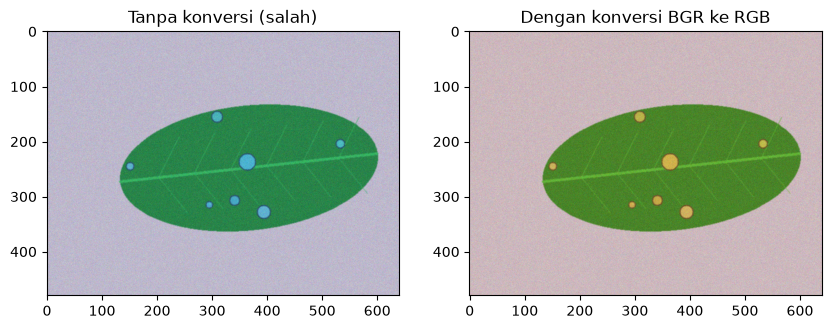

In [6]:
import sys
sys.path.append("../src") # agar utils_cv dapat diimpor dari notebook/
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil
print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])
# tampilkan citra TANPA dan DENGAN konversi BGR ke RGB
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.savefig("../hasil/b1_bgr_rgb.png")
plt.show()

In [7]:
# Bukti pendukung P1.1 dan P1.3: nilai piksel yang sama dibaca sebagai BGR vs RGB
b, g, r = img[100, 200]
print(f"Piksel (y=100, x=200): B={b}, G={g}, R={r}")
print(f"Jika salah dibaca sebagai RGB: R={b}, G={g}, B={r}")

Piksel (y=100, x=200): B=183, G=180, R=228
Jika salah dibaca sebagai RGB: R=183, G=180, B=228


## Problem statement
Bagi petugas sortir kelompok tani teh rakyat di Kabupaten Sukabumi yang menilai bercak daun secara manual dengan hasil yang lambat dan berbeda antarpetugas, terutama saat cahaya tidak merata dan bercak masih kecil, kami membangun SIMUTEH, sistem pemeriksaan mutu daun berbasis citra, yang menerima foto satu helai daun di atas nampan dari kamera handphone dan menghasilkan kelas mutu (Sehat, Bercak Ringan, Bercak Berat) beserta persentase luas bercak, sehingga petugas memperoleh pertimbangan yang konsisten sementara keputusan akhir tetap di tangan petugas.

## Diagram pipeline SIMUTEH (enam tahap)

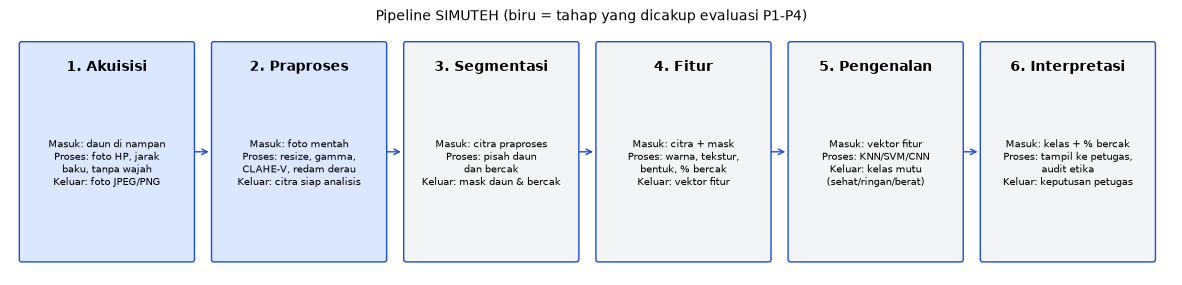

In [8]:
import matplotlib.patches as mp
tahap = [
 ("1. Akuisisi",      "Masuk: daun di nampan\nProses: foto HP, jarak\nbaku, tanpa wajah\nKeluar: foto JPEG/PNG"),
 ("2. Praproses",     "Masuk: foto mentah\nProses: resize, gamma,\nCLAHE-V, redam derau\nKeluar: citra siap analisis"),
 ("3. Segmentasi",    "Masuk: citra praproses\nProses: pisah daun\ndan bercak\nKeluar: mask daun & bercak"),
 ("4. Fitur",         "Masuk: citra + mask\nProses: warna, tekstur,\nbentuk, % bercak\nKeluar: vektor fitur"),
 ("5. Pengenalan",    "Masuk: vektor fitur\nProses: KNN/SVM/CNN\nKeluar: kelas mutu\n(sehat/ringan/berat)"),
 ("6. Interpretasi",  "Masuk: kelas + % bercak\nProses: tampil ke petugas,\naudit etika\nKeluar: keputusan petugas"),
]
fig, ax = plt.subplots(figsize=(15, 3.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 3.2); ax.axis("off")
for i, (jd, isi) in enumerate(tahap):
    x = 0.15 + i * 2.48
    warna = "#dbe7ff" if i < 2 else "#f3f4f6"
    ax.add_patch(mp.FancyBboxPatch((x, 0.2), 2.2, 2.8, boxstyle="round,pad=0.03", fc=warna, ec="#1d4ed8"))
    ax.text(x + 1.1, 2.7, jd, ha="center", va="center", fontsize=10, fontweight="bold")
    ax.text(x + 1.1, 1.45, isi, ha="center", va="center", fontsize=7.5)
    if i < 5:
        ax.annotate("", xy=(x + 2.45, 1.6), xytext=(x + 2.2, 1.6), arrowprops=dict(arrowstyle="->", color="#1d4ed8"))
ax.set_title("Pipeline SIMUTEH (biru = tahap yang dicakup evaluasi P1-P4)", fontsize=10)
plt.savefig("../hasil/b1_pipeline.png", dpi=150, bbox_inches="tight"); plt.show()

## Tabel 6. Risiko responsible computer vision SIMUTEH
| Aspek | Risiko pada SIMUTEH | Mitigasi awal |
|---|---|---|
| Privasi citra | Wajah petani ikut terfoto dan EXIF memuat koordinat GPS kebun | Bingkai hanya daun dan nampan, GPS kamera dimatikan, EXIF dihapus sebelum foto dibagikan, izin tertulis ketua kelompok tani |
| Bias dan keadilan | Data sintetis tidak mewakili klon, umur daun, dan penyakit lain, sehingga akurasi bisa timpang antarkondisi cahaya | Laporkan hasil per kondisi cahaya, uji pada foto nyata sebelum dipakai, tidak mengklaim akurat di luar kondisi uji |
| Transparansi | Petugas tidak tahu dasar penilaian sistem dan kapan sistem kurang yakin | Tampilkan persentase bercak dan mask-nya, beri peringatan bila cahaya di luar rentang uji, jelaskan batas sistem |
| Keamanan data | Foto dan lokasi kebun tersebar lewat repositori atau tautan terbuka | Repositori privat, data mentah tidak diunggah, akses hanya anggota tim dan dosen |
| Dampak sosial | Daun sehat dinilai berat merugikan petani (harga turun), daun berat dinilai sehat membiarkan penyakit menyebar | Sistem hanya alat bantu, keputusan akhir di petugas, sampel acak diperiksa ulang manual |
| Keterlacakan | Hasil tidak dapat diulang karena parameter dan data tidak tercatat | Parameter di JSON, SEED dicatat, commit bertahap, tag versi, `requirements.txt` |